# Tarea 3 - Reconocimiento de Patrones en Imágenes

**Laura Romero 🇮🇹 y Javier Oberto** 👅

---

### Instrucciones de uso
1. crear entorno virtual de pyhton
    *python -m venv 'nombre del env'*

    *source 'nombre del env'/bin/activate*

2. Colocar la carpeta `BD/` en el mismo directorio que este notebook.
3. Ejecutar las celdas en orden de arriba hacia abajo.
4. La celda de SBS puede tardar en ejecutar, a la calma nomas.
5. paso 5: disfrutar

In [65]:
!pip install opencv-python
!pip install matplotlib
!pip install pandas
!pip install scipy
!pip install scikit-learn
!pip install scikit-image

In [66]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
from skimage.feature import graycomatrix, graycoprops
from sklearn import preprocessing
from math import radians
import os
import glob

---
## Parte I: Construcción de la Base de Datos
Construimos la 'Base de datos'(tabla glorificada) donde extraemos 6 descriptores de la matriz de con ocurrencia (GLCM) por cada canal (R, G, B y escala de grises), lo que nos da 24 características por imagen. Usamos los mismos parámetros que en clases: distancia=1, ángulo=90°, 16 niveles de gris.

In [67]:
# propiedasdes a extraer(en ingles pq nos creemos bilingues)
features_glcm = ['contrast', 'correlation', 'dissimilarity', 'homogeneity', 'ASM', 'energy']

canales = ['R', 'G', 'B', 'gray']

nombres_columnas = []
for canal in canales:
    for feat in features_glcm:
        nombres_columnas.append(f'{canal}_{feat}')

print(nombres_columnas)

['R_contrast', 'R_correlation', 'R_dissimilarity', 'R_homogeneity', 'R_ASM', 'R_energy', 'G_contrast', 'G_correlation', 'G_dissimilarity', 'G_homogeneity', 'G_ASM', 'G_energy', 'B_contrast', 'B_correlation', 'B_dissimilarity', 'B_homogeneity', 'B_ASM', 'B_energy', 'gray_contrast', 'gray_correlation', 'gray_dissimilarity', 'gray_homogeneity', 'gray_ASM', 'gray_energy']


In [68]:
# leemos las carpetas de texturas
carpetas = sorted(glob.glob('BD/textura_*'))


# aqui guardamos todos los descriptores y las clases
F = []
etiquetas = []

for carpeta in carpetas:
    
    clase = int(carpeta.split('_')[-1])
    archivos = sorted(glob.glob(os.path.join(carpeta, '*.jpg')))

    for archivo in archivos:
        
        img = cv2.imread(archivo)

       
        blue, green, red = cv2.split(img)

        
        gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)

       
        descriptores_imagen = []

        for canal in [red, green, blue, gray]:
            
            canal_col = canal.reshape(-1, 1)
            canal_escalado = preprocessing.MinMaxScaler((0, 15)).fit_transform(canal_col).astype(int)
            canal_escalado = canal_escalado.reshape(canal.shape)

            
            niveles = np.max(canal_escalado) + 1
            glcm = graycomatrix(canal_escalado, distances=[1], angles=[radians(90)],
                                levels=niveles, symmetric=False, normed=False)

            
            for feat in features_glcm:
                valor = graycoprops(glcm, feat).squeeze()
                descriptores_imagen.append(float(valor))

        F.append(descriptores_imagen)
        etiquetas.append(clase)

# armamos el dataframe
df = pd.DataFrame(F, columns=nombres_columnas)
df['clase'] = etiquetas

print('el dataset quedo de', df.shape)

print(df.head(10))

el dataset quedo de (500, 25)
   R_contrast  R_correlation  R_dissimilarity  R_homogeneity     R_ASM  \
0    0.941880       0.956000         0.645333       0.706354  0.033025   
1    0.995550       0.958397         0.669478       0.697254  0.030814   
2    1.037446       0.955108         0.677639       0.696295  0.031582   
3    1.022651       0.955103         0.670522       0.698992  0.032347   
4    1.175100       0.944109         0.741044       0.671738  0.027449   
5    1.164048       0.945643         0.735968       0.673645  0.027563   
6    1.089719       0.947417         0.712016       0.680989  0.030702   
7    1.169703       0.945249         0.751550       0.665106  0.028122   
8    1.095454       0.940943         0.732466       0.669534  0.029346   
9    1.088948       0.940357         0.745494       0.661246  0.027611   

   R_energy  G_contrast  G_correlation  G_dissimilarity  G_homogeneity  ...  \
0  0.181729    1.083213       0.958979         0.698313       0.688203  ... 

---
## Parte II: Normalización
Normalizamos cada columna con media cero y desviación uno usando `StandardScaler` igual que en clases.

In [69]:
from sklearn.preprocessing import StandardScaler

# separamos features y etiquetas
X = df[nombres_columnas].values
y = df['clase'].values

# normalizamos: media=0, desviacion=1
escala = StandardScaler()
X_norm = escala.fit_transform(X)


print(np.round(X_norm.mean(axis=0), 4))
print()
print(np.round(X_norm.std(axis=0), 4))

# lo guardamos en un dataframe para tenerlo organizado
df_norm = pd.DataFrame(X_norm, columns=nombres_columnas)
df_norm['clase'] = y
print('\ndataset normalizado:', df_norm.shape)

[-0.  0. -0.  0.  0.  0. -0. -0. -0.  0. -0. -0.  0. -0. -0.  0. -0.  0.
 -0. -0. -0. -0. -0. -0.]

[1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1.]

dataset normalizado: (500, 25)


---
## Parte III: Selección de Características (SBS + Fisher)
Usamos la Sequential Backward Selection: partiendo des 24 características vamos eliminando la peor de a una, quedándonos con la combinación que maximiza el índice de Fisher en cada paso.

La función de Fisher viene directo de lo visto en la clase 15.

In [70]:
from numpy.linalg import inv
from numpy.matlib import repmat
from itertools import combinations

# funcion que calcula el indice de Fisher
def fisher_extraction_list(data, cols, clases):
    if cols == 1:
        D = np.hstack(data)
        total = len(D)
        Vm = np.mean(D)
    else:
        D = np.vstack(data)
        Vm = np.mean(D, axis=0)
        total = D.shape[0]

    p = np.zeros((clases, 1))
    Vk = np.zeros((clases, cols))
    Gn = []

    for i in range(clases):
        Vk[i, :] = np.mean(data[i], axis=0)
        pts = data[i].shape[0]
        if cols == 1:
            Gn.append(data[i] - Vm)
        else:
            Gn.append(data[i] - repmat(Vm, pts, 1))
        p[i] = data[i].shape[0] / total

    Cb = np.zeros((cols, cols))
    Cw = np.zeros((cols, cols))

    for k in range(clases):
        Cb = Cb + p[k] * np.matmul((Vk[k, :] - Vm).reshape(cols, 1),
                                    (Vk[k, :] - Vm).reshape(1, cols))
        MGn = np.array(Gn[k])
        Cw = Cw + p[k] * np.cov(MGn.T)

    J = np.trace(np.matmul(inv(Cw), Cb))
    return J

In [71]:
# funcion SBS 

def sbs_procedure(X_data, clases, feature_names, sel_features):
    cols = X_data.shape[1]
    id_clases = np.unique(clases)
    u_clases = len(id_clases)

    indices_actuales = np.arange(cols)
    historial_J = []
    historial_features = []

    t = cols
    while t > sel_features:
        combs = np.array(list(combinations(indices_actuales, len(indices_actuales) - 1)))
        J = np.zeros(len(combs))

        for i in range(len(combs)):
            feat = combs[i]
            sub_data = []
            for k in id_clases:
                id_class = clases == k
                sub_data.append(X_data[id_class][:, feat])

            J[i] = fisher_extraction_list(sub_data, len(feat), u_clases)

        best = np.argmax(J)
        indices_actuales = combs[best]
        best_J = J[best]

        historial_J.append(best_J)
        historial_features.append(feature_names[indices_actuales].copy())

        print(f'  quedan {len(indices_actuales)} features, Fisher = {best_J:.4f}')
        t = t - 1

    return indices_actuales, historial_J, historial_features

In [72]:
# corremos SBS desde 24 features hasta un minimo de 3 caracteristicas(para evaluar cual maximiza ficher)
feature_names = np.array(nombres_columnas)

print('corriendo SBS, esto tarda un poco \n')
indices_sel, historial_J, historial_features = sbs_procedure(X_norm, y, feature_names, 3)

print('\nal final quedaron estas 3:', list(feature_names[indices_sel]))

corriendo SBS, esto tarda un poco 

  quedan 23 features, Fisher = 45.4631
  quedan 22 features, Fisher = 45.2664
  quedan 21 features, Fisher = 45.0329
  quedan 20 features, Fisher = 44.5622
  quedan 19 features, Fisher = 44.0086
  quedan 18 features, Fisher = 42.8872
  quedan 17 features, Fisher = 41.6501
  quedan 16 features, Fisher = 41.0287
  quedan 15 features, Fisher = 39.7017
  quedan 14 features, Fisher = 38.0692
  quedan 13 features, Fisher = 36.3455
  quedan 12 features, Fisher = 34.8912
  quedan 11 features, Fisher = 33.0350
  quedan 10 features, Fisher = 30.2742
  quedan 9 features, Fisher = 27.7438
  quedan 8 features, Fisher = 25.1742
  quedan 7 features, Fisher = 22.9133
  quedan 6 features, Fisher = 20.0153
  quedan 5 features, Fisher = 18.3318
  quedan 4 features, Fisher = 15.1001
  quedan 3 features, Fisher = 12.1584

al final quedaron estas 3: [np.str_('gray_contrast'), np.str_('gray_correlation'), np.str_('gray_dissimilarity')]


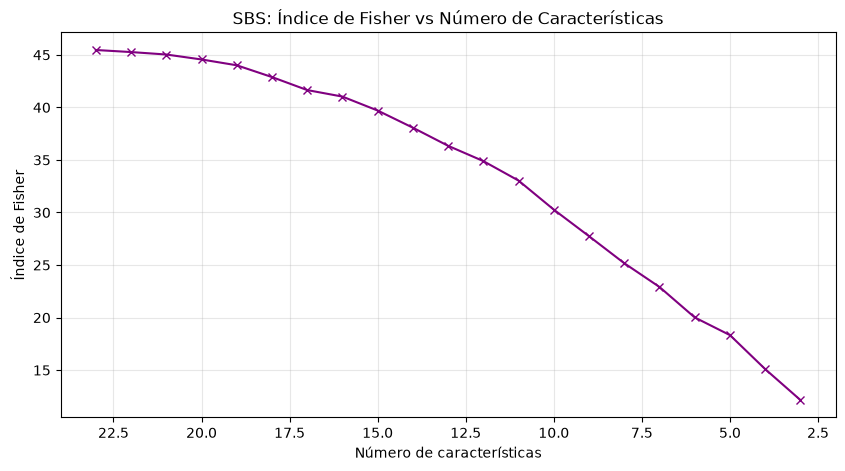

In [73]:
# graficamos Fisher vs numero de caracteristicas para ver la tendencia
n_features_list = list(range(23, 2, -1))

plt.figure(figsize=(10, 5))
plt.plot(n_features_list, historial_J, 'x-', color='purple')
plt.xlabel('Número de características')
plt.ylabel('Índice de Fisher')
plt.title('SBS: Índice de Fisher vs Número de Características')
plt.grid(alpha=0.3)
plt.gca().invert_xaxis()
plt.show()

### De Aqui vemos que la tendencia es que entre mas caracteristicas quitamos, mas disminuye el indice de ficher 
Por lo tanto hay que mantener la mayor cantidad de caracteristicas antes de que baje de 45, por lo que nos quedamos por ahora con 20 caracteristicas

Aun asi, como lo dice la tarea, probamos al menos 5 valores a continuación

In [74]:
# probamos con 5 valores distintos 
valores_a_probar = [20, 15, 10, 7, 5]

print('vemos como queda Fisher con distintas cantidades:\n')
print(f'{"N features":<12} {"Fisher":<12} ')
print('-' * 20)

for n in valores_a_probar:
    idx = 23 - n
    if 0 <= idx < len(historial_J):
        feats_str = ', '.join(historial_features[idx])
        print(f'{n:<12} {historial_J[idx]:<12.4f} ')

vemos como queda Fisher con distintas cantidades:

N features   Fisher       
--------------------
20           44.5622      
15           39.7017      
10           30.2742      
7            22.9133      
5            18.3318      


### Ahora evaluamos un clasificador de verdad
El Fisher nos dice que tan separadas quedan las clases, pero el enunciado pide elegir el numero de caracteristicas que maximice el rendimiento del clasificador por lo que no solo el Fisher. Entonces usamos el clasificador de distancia minima (distancia de Mahalanobis) que vimos en la clase 17 que para cada clase calcula su media y covarianza con los datos de entrenamiento, y cada punto de prueba se asigna a la clase mas cercana.

Separamos los datos en 70% entrenamiento y 30% prueba (clase por clase, para mantener las proporciones) y medimos el accuracy para los mismos 5 valores de caracteristicas de la tabla de arriba.

Importante: para esta parte normalizamos de nuevo, pero ajustando la media y desviacion solo con los datos de entrenamiento (no con el X_norm de la Parte II, que se calculo con las 500 muestras juntas). para que test quede realmente "afuera" y no exista data leakage de el hacia la normalizacion.

In [75]:
def clasificador_mahalanobis(X_train, y_train, X_test):
    clases_unicas = np.unique(y_train)

    medias = {}
    inv_covs = {}
    for clase in clases_unicas:
        datos_clase = X_train[y_train == clase]
        medias[clase] = datos_clase.mean(axis=0)
        cov_clase = np.cov(datos_clase.T)
       
        cov_clase = cov_clase + np.eye(cov_clase.shape[0]) * 1e-6
        inv_covs[clase] = np.linalg.inv(cov_clase)

    predicciones = []
    for punto in X_test:
        distancias = []
        for clase in clases_unicas:
            diff = (punto - medias[clase]).reshape(1, -1)
            d = diff @ inv_covs[clase] @ diff.T
            distancias.append(d[0, 0])
        predicciones.append(clases_unicas[np.argmin(distancias)])

    return np.array(predicciones)

In [76]:
def split_train_test(X, y, porc_train=0.7, seed=42):
    rng = np.random.default_rng(seed)
    idx_train = []
    idx_test = []
    for clase in np.unique(y):
        idx_clase = np.where(y == clase)[0]
        rng.shuffle(idx_clase)
        corte = int(len(idx_clase) * porc_train)
        idx_train.extend(idx_clase[:corte])
        idx_test.extend(idx_clase[corte:])
    return np.array(idx_train), np.array(idx_test)

idx_train, idx_test = split_train_test(X_norm, y)
print('muestras de entrenamiento:', len(idx_train))
print('muestras de prueba:', len(idx_test))

muestras de entrenamiento: 350
muestras de prueba: 150


In [77]:
resultados_accuracy = []

print('accuracy del clasificador para cada cantidad de caracteristicas:\n')
for n in valores_a_probar:
    idx = 23 - n
    feats = historial_features[idx]
    cols = [nombres_columnas.index(f) for f in feats]

    X_n = X[:, cols]  # datos SIN normalizar (de la Parte I)
    X_train_raw, y_train = X_n[idx_train], y[idx_train]
    X_test_raw, y_test = X_n[idx_test], y[idx_test]

    escala_cv = StandardScaler()
    X_train = escala_cv.fit_transform(X_train_raw)
    X_test = escala_cv.transform(X_test_raw)

    y_pred = clasificador_mahalanobis(X_train, y_train, X_test)
    accuracy = np.mean(y_pred == y_test)
    resultados_accuracy.append(accuracy)

    print(f'  {n} features -> accuracy = {accuracy:.4f}')

accuracy del clasificador para cada cantidad de caracteristicas:

  20 features -> accuracy = 0.9267
  15 features -> accuracy = 0.9267
  10 features -> accuracy = 0.9200
  7 features -> accuracy = 0.9133
  5 features -> accuracy = 0.9133


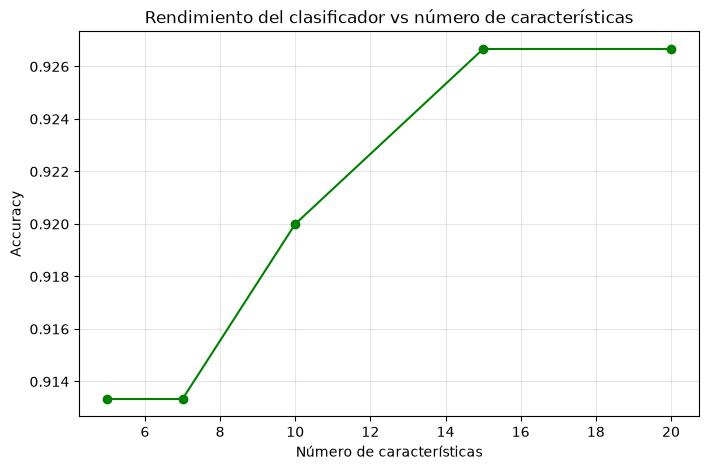

In [78]:
# graficamos el accuracy vs el numero de caracteristicas
plt.figure(figsize=(8, 5))
plt.plot(valores_a_probar, resultados_accuracy, 'o-', color='green')
plt.xlabel('Número de características')
plt.ylabel('Accuracy')
plt.title('Rendimiento del clasificador vs número de características')
plt.grid(alpha=0.3)
plt.show()

#### De aqui vemos que el numero minimo de caracteristicas que maximiza el accuracy es de 15, con mas el accuracy queda igual

In [79]:
n_elegido = 15  
idx_elegido = 23 - n_elegido
mejor_features = historial_features[idx_elegido]
indices_mejor = [nombres_columnas.index(f) for f in mejor_features]
X_sel = X_norm[:, indices_mejor]

print(f'\nelegimos {n_elegido} caracteristicas')
print('Fisher:', round(historial_J[idx_elegido], 4))
print('features:', list(mejor_features))
print('quedo de', X_sel.shape)


elegimos 15 caracteristicas
Fisher: 39.7017
features: [np.str_('R_contrast'), np.str_('R_correlation'), np.str_('R_dissimilarity'), np.str_('R_homogeneity'), np.str_('R_ASM'), np.str_('R_energy'), np.str_('G_correlation'), np.str_('B_contrast'), np.str_('B_correlation'), np.str_('B_dissimilarity'), np.str_('B_energy'), np.str_('gray_contrast'), np.str_('gray_correlation'), np.str_('gray_dissimilarity'), np.str_('gray_energy')]
quedo de (500, 15)


---
## Parte IV: Compresión con VQ (Vector Quantization)
Aplicamos kmeans de scipy para reducir las 500 muestras a ~100 centroides, tal como se vio en la clase 13. Luego graficamos los centroides sobre los pares de características más representativos.

In [80]:
from scipy.cluster import vq


obs = vq.whiten(X_sel)


n_centroides = 100
cbk, distortion = vq.kmeans(obs, n_centroides, iter=20)

print('muestras originales:', obs.shape[0])
print('centroides que salieron:', cbk.shape[0])
print('distorsion:', round(distortion, 4))

muestras originales: 500
centroides que salieron: 100
distorsion: 0.357


In [81]:
asignaciones, _ = vq.vq(obs, cbk)


clases_centroides = []
for c in range(cbk.shape[0]):
    mask = asignaciones == c
    if np.sum(mask) > 0:
        clase_c = int(np.bincount(y[mask].astype(int)).argmax())
        clases_centroides.append(clase_c)
    else:
        clases_centroides.append(0)

clases_centroides = np.array(clases_centroides)
print('clases en los centroides:', np.unique(clases_centroides))
print('centroides por clase:')
for clase in np.unique(clases_centroides):
    if clase > 0:
        print(f'  textura {int(clase)}: {np.sum(clases_centroides == clase)}')

clases en los centroides: [ 1  2  3  4  5  6  7  8  9 10]
centroides por clase:
  textura 1: 6
  textura 2: 6
  textura 3: 12
  textura 4: 11
  textura 5: 11
  textura 6: 11
  textura 7: 10
  textura 8: 11
  textura 9: 10
  textura 10: 12


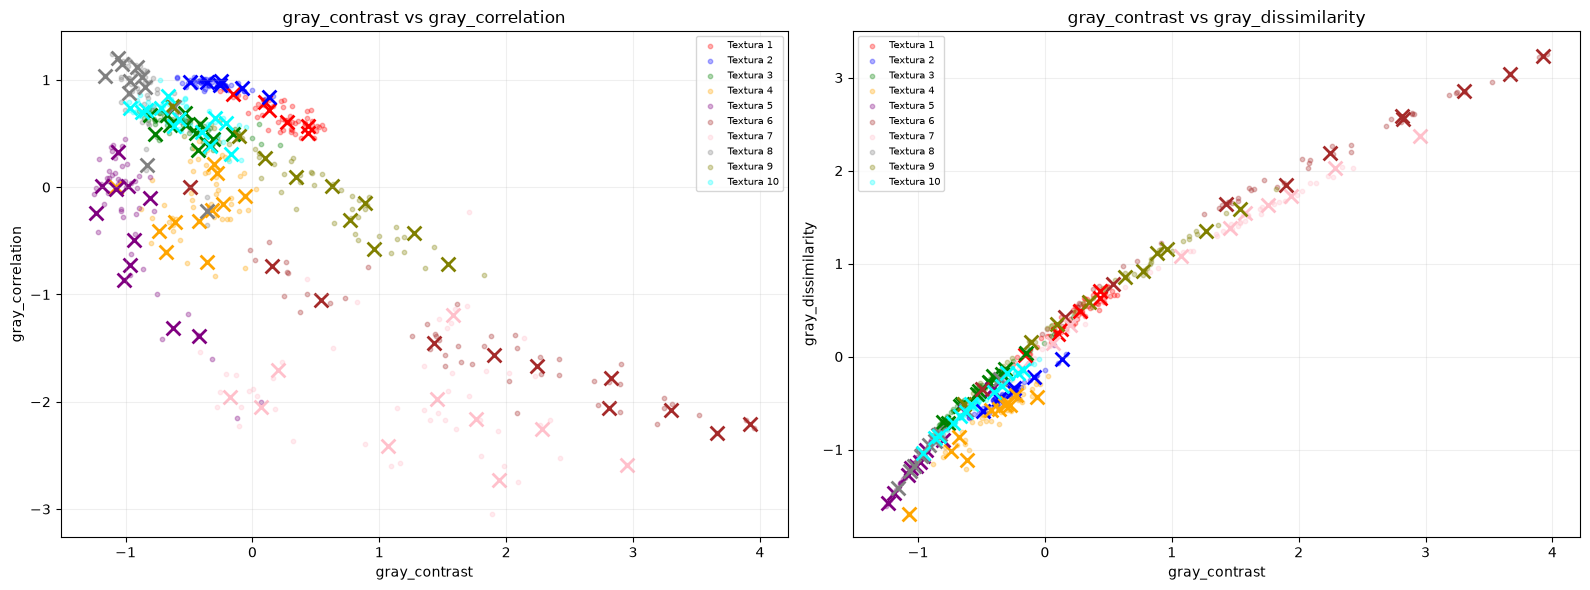

In [82]:
mejores_3 = list(feature_names[indices_sel])
idx_best = [list(mejor_features).index(f) for f in mejores_3]

colores = ['red', 'blue', 'green', 'orange', 'purple',
           'brown', 'pink', 'gray', 'olive', 'cyan']

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# grafico 1: mejor feature 0 vs mejor feature 1
ax = axes[0]
for clase in np.unique(y):
    mask = y == clase
    ax.scatter(obs[mask, idx_best[0]], obs[mask, idx_best[1]],
               c=colores[int(clase) - 1], s=10, alpha=0.3, label=f'Textura {int(clase)}')
for clase in np.unique(clases_centroides):
    if clase == 0:
        continue
    mask_c = clases_centroides == clase
    ax.scatter(cbk[mask_c, idx_best[0]], cbk[mask_c, idx_best[1]],
               c=colores[int(clase) - 1], marker='x', s=100, linewidths=2)

ax.set_xlabel(mejores_3[0])
ax.set_ylabel(mejores_3[1])
ax.set_title(f'{mejores_3[0]} vs {mejores_3[1]}')
ax.legend(fontsize=7, loc='best')
ax.grid(alpha=0.2)


ax = axes[1]
for clase in np.unique(y):
    mask = y == clase
    ax.scatter(obs[mask, idx_best[0]], obs[mask, idx_best[2]],
               c=colores[int(clase) - 1], s=10, alpha=0.3, label=f'Textura {int(clase)}')
for clase in np.unique(clases_centroides):
    if clase == 0:
        continue
    mask_c = clases_centroides == clase
    ax.scatter(cbk[mask_c, idx_best[0]], cbk[mask_c, idx_best[2]],
               c=colores[int(clase) - 1], marker='x', s=100, linewidths=2)

ax.set_xlabel(mejores_3[0])
ax.set_ylabel(mejores_3[2])
ax.set_title(f'{mejores_3[0]} vs {mejores_3[2]}')
ax.legend(fontsize=7, loc='best')
ax.grid(alpha=0.2)

plt.tight_layout()
plt.show()

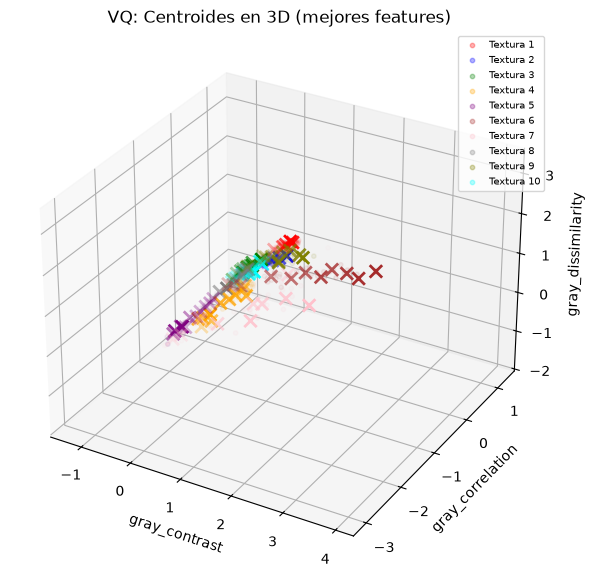

In [83]:
# grafico 3D con las 3 mejores caracteristicas
fig = plt.figure(figsize=(10, 7))
ax = fig.add_subplot(projection='3d')

for clase in np.unique(y):
    mask = y == clase
    ax.scatter(obs[mask, idx_best[0]], obs[mask, idx_best[1]], obs[mask, idx_best[2]],
               c=colores[int(clase) - 1], s=10, alpha=0.3, label=f'Textura {int(clase)}')

for clase in np.unique(clases_centroides):
    if clase == 0:
        continue
    mask_c = clases_centroides == clase
    ax.scatter(cbk[mask_c, idx_best[0]], cbk[mask_c, idx_best[1]], cbk[mask_c, idx_best[2]],
               c=colores[int(clase) - 1], marker='x', s=80, linewidths=2)

ax.set_xlabel(mejores_3[0])
ax.set_ylabel(mejores_3[1])
ax.set_zlabel(mejores_3[2])
ax.set_title('VQ: Centroides en 3D (mejores features)')
ax.legend(fontsize=7, loc='best')
plt.show()